# Clustering: Perfiles de Sueño y Tiempo de Pantalla

Este notebook busca responder qué perfiles de hábitos de sueño y de tiempo de pantalla existen entre los adolescentes y cómo se distribuyen la depresión y el sexo entre ellos. A diferencia del modelado, el análisis es descriptivo: no se predice nada, sino que se agrupa a los adolescentes con K-Means según sus hábitos y después se examina cómo se reparten, en cada grupo, las variables que no participaron en su formación.

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

pd.set_option("display.max_colwidth", None)

from Clustering import (
    SEED, VARIABLES_CLUSTER, RANGO_K, N_INIT, N_BOOTSTRAP,
    cargar_dataset, nombre_variable, completar_nombres,
    evaluar_k, graficar_seleccion_k, ajustar_final,
    tabla_tamanos, tabla_medias_medianas, perfiles_estandarizados, graficar_perfiles, graficar_pca, cargas_pca,
    prueba_chi_cuadrado, prevalencia_por_cluster, graficar_prevalencia,
    resumen_bdi, prueba_kruskal, comparaciones_por_pares, graficar_bdi,
    composicion_sexo, graficar_sexo,
    tabla_perfiles, guardar_resultados,
)

### Datos y Variables

Se usa el dataset completo, sin dividir en train y test, porque el objetivo es describir y no predecir. Los clusters se forman únicamente con las cinco variables de hábitos: el índice de calidad del sueño, las horas de sueño promedio, el punto medio del sueño del fin de semana, el jet lag social y el índice de tiempo de pantalla. El BDI-II, el estado depresivo y el sexo quedan fuera a propósito y solo se usan después para describir los perfiles. Si la depresión entrara en el agrupamiento, los clusters la reflejarían por construcción y la diferencia de prevalencia entre ellos no diría nada sobre la relación entre hábitos y depresión; lo mismo ocurriría con el sexo.

Las variables se estandarizan con un `StandardScaler` dentro de un Pipeline (`StandardScaler` → `KMeans`), ya que K-Means usa distancias euclídeas y, sin estandarizar, dominarían las variables con mayor escala. Conviene tener presente que el punto medio del sueño y el jet lag social están fuertemente correlacionados (r = 0.84 en el EDA), por lo que el dominio de horarios de sueño pesa algo más que los demás en la distancia.

In [2]:
df = cargar_dataset()
X = df[VARIABLES_CLUSTER]

resumen = X.agg(["mean", "std", "min", "max"]).T
resumen.index = [nombre_variable(v) for v in resumen.index]
resumen.columns = ["Media", "DE", "Mínimo", "Máximo"]
print(f"Adolescentes: {len(X)}")
resumen.round(3)

Adolescentes: 4810


,Media,DE,Mínimo,Máximo
Índice de calidad del sueño,1.902,0.851,1.00,6.00
Horas de sueño promedio,7.689,1.270,1.36,12.21
Punto medio del sueño (fin de semana),5.571,1.416,1.67,10.50
Jet lag social,2.400,1.138,-3.03,6.96
Índice de tiempo de pantalla,3.219,1.026,1.00,6.00


## 1. Elección del Número de Clusters

Se prueban valores de k entre 2 y 8 con `KMeans(n_init=50, random_state=SEED)` y, para cada uno, se calculan cuatro métricas internas sobre los datos estandarizados. La inercia, la suma de las distancias al cuadrado de cada adolescente a su centroide, siempre disminuye al aumentar k, por lo que se busca el punto a partir del cual deja de bajar de forma apreciable (método del codo). El coeficiente de silueta, entre −1 y 1, compara la cercanía de cada adolescente a su cluster con la del cluster vecino; el índice de Davies-Bouldin mide la similitud media entre cada cluster y el más parecido, de modo que valores bajos indican clusters más separados; y el índice de Calinski-Harabasz compara la dispersión entre clusters con la dispersión dentro de ellos, con valores altos como mejores.

A estas métricas se suma la estabilidad. Para cada k se ajusta K-Means en 50 submuestras bootstrap, cada una con un `random_state` derivado de `SEED`, se asigna con cada modelo a todos los adolescentes y se mide con el índice de Rand ajustado (ARI) cuánto coinciden esas asignaciones con las del modelo ajustado con todos los datos. Un ARI cercano a 1 indica que la partición se reproduce aunque cambie la muestra, y uno bajo, que depende de qué adolescentes se incluyan.

Es esperable una silueta baja, del orden de 0.2 a 0.3, porque el EDA mostró que estas variables varían de forma continua y no forman grupos naturales bien separados. Por eso los clusters se interpretan como una segmentación útil de los adolescentes en perfiles, y no como tipos reales y diferenciados de adolescentes.

In [3]:
print(f"k de {min(RANGO_K)} a {max(RANGO_K)}, n_init = {N_INIT}, {N_BOOTSTRAP} réplicas bootstrap por k")
tabla_k = evaluar_k(X, seed=SEED)
tabla_k.set_index("k").round(3)

k de 2 a 8, n_init = 50, 50 réplicas bootstrap por k
✓ k = 2: silueta = 0.289, ARI = 0.972 ± 0.018
✓ k = 3: silueta = 0.270, ARI = 0.907 ± 0.066
✓ k = 4: silueta = 0.206, ARI = 0.619 ± 0.252
✓ k = 5: silueta = 0.209, ARI = 0.806 ± 0.120
✓ k = 6: silueta = 0.197, ARI = 0.861 ± 0.066
✓ k = 7: silueta = 0.201, ARI = 0.821 ± 0.095
✓ k = 8: silueta = 0.192, ARI = 0.707 ± 0.111


,inercia,silueta,davies_bouldin,calinski_harabasz,ari_media,ari_desviacion
k,,,,,,
2,16855.121,0.289,1.410,2052.373,0.972,0.018
3,14452.788,0.270,1.467,1596.021,0.907,0.066
4,12886.115,0.206,1.480,1387.899,0.619,0.252
5,11438.150,0.209,1.315,1324.520,0.806,0.120
6,10441.539,0.197,1.401,1252.215,0.861,0.066
7,9805.248,0.201,1.357,1162.941,0.821,0.095
8,9270.499,0.192,1.342,1093.657,0.707,0.111


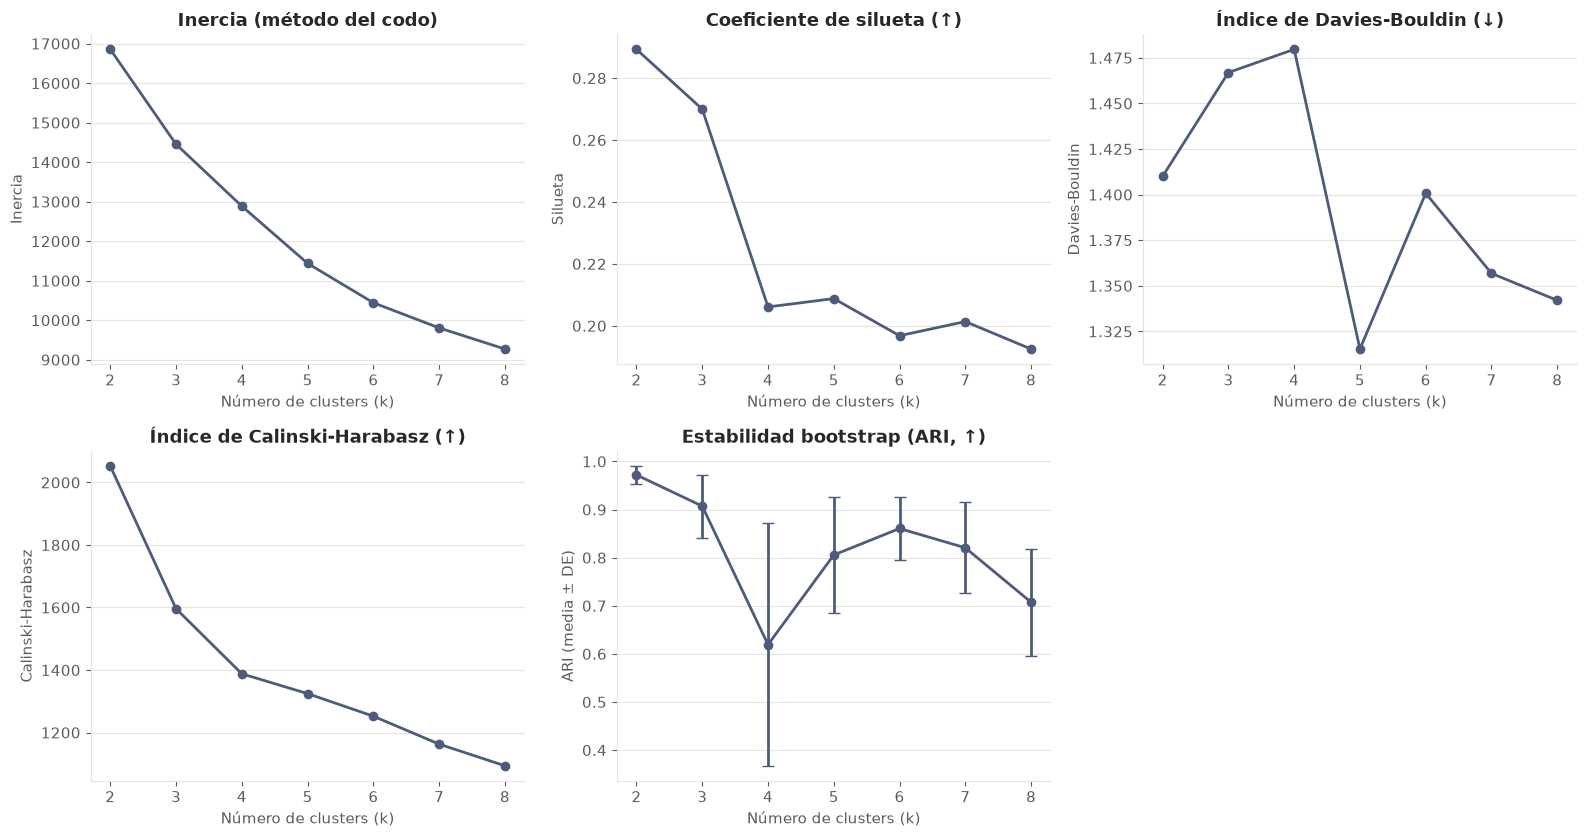

In [4]:
fig = graficar_seleccion_k(tabla_k)
plt.show()

Las métricas no apuntan a un único valor de k. La inercia disminuye de forma gradual, de 16855.121 con k = 2 a 9270.499 con k = 8, sin un codo definido. La silueta y el índice de Calinski-Harabasz son máximos con k = 2 (0.289 y 2052.373), bajan con k = 3 (0.270 y 1596.021) y, a partir de k = 4, la silueta se estabiliza entre 0.192 y 0.209. El índice de Davies-Bouldin, en cambio, alcanza su mínimo con k = 5 (1.315) y es más alto con k = 3 y k = 4 (1.467 y 1.480). La estabilidad favorece las particiones con pocos clusters: el ARI es de 0.972 ± 0.018 con k = 2 y de 0.907 ± 0.066 con k = 3, cae a 0.619 ± 0.252 con k = 4, el valor más bajo y más variable de todos, y se recupera en parte con k = 5 (0.806 ± 0.120) y k = 6 (0.861 ± 0.066).

Se elige k = 3. Dos clusters quedan por debajo del rango de 3 a 5 perfiles que se busca describir, y dentro de ese rango k = 3 reúne la mayor silueta (0.270), el mayor índice de Calinski-Harabasz (1596.021) y la partición más estable (ARI de 0.907 ± 0.066); k = 5 solo lo supera en Davies-Bouldin, con una estabilidad menor, y k = 4 se descarta por su inestabilidad. Como se anticipaba, la silueta es baja incluso con el k elegido, lo que confirma que los clusters segmentan un continuo de hábitos más que separar grupos naturales.

In [5]:
# Elegido tras ver la tabla y los gráficos de selección de k
K_ELEGIDO = 3

pipeline, etiquetas = ajustar_final(X, K_ELEGIDO, seed=SEED)

tabla_k.set_index("k").loc[[K_ELEGIDO]].round(3)

,inercia,silueta,davies_bouldin,calinski_harabasz,ari_media,ari_desviacion
k,,,,,,
3,14452.788,0.27,1.467,1596.021,0.907,0.066


## 2. Descripción de los Perfiles

Cada cluster recibe un nombre corto que resume su perfil, definido después de ver el gráfico de perfiles. Los nombres se guardan en el diccionario de la celda siguiente, de modo que todas las tablas y gráficos posteriores los usen; mientras no se completen, cada cluster se identifica por su número.

In [6]:
# Nombres definidos a partir del gráfico de perfiles
NOMBRES_CLUSTERS = {
    0: "Sueño largo y regular",
    1: "Sueño corto y de mala calidad",
    2: "Horario tardío y jet lag social",
}
nombres = completar_nombres(NOMBRES_CLUSTERS, K_ELEGIDO)

tabla_tamanos(etiquetas, nombres)

,Nombre,n,%
Cluster,,,
0,Sueño largo y regular,2586,53.8
1,Sueño corto y de mala calidad,712,14.8
2,Horario tardío y jet lag social,1512,31.4


In [7]:
# Unidades originales de cada variable
tabla_medias_medianas(X, etiquetas).round(2)

Índice de calidad del sueño         Horas de sueño promedio          \
                              Media Mediana                   Media Mediana   
Cluster                                                                       
0                              1.66    1.50                    8.31    8.33   
1                              3.27    3.25                    6.19    6.40   
2                              1.67    1.50                    7.34    7.44   

        Punto medio del sueño (fin de semana)         Jet lag social          \
                                        Media Mediana          Media Mediana   
Cluster                                                                        
0                                        4.62    4.67           1.75    1.75   
1                                        6.18    6.04           2.34    2.33   
2                                        6.91    6.78           3.54    3.42   

        Índice de tiempo de pantalla          
                               Media Mediana  
Cluster                                       
0                               2.86    2.67  
1                               3.72    3.67  
2                               3.60    3.67

El gráfico de perfiles es la herramienta principal para interpretar los clusters. Muestra, para cada cluster, la media de cada variable estandarizada, es decir, cuántas desviaciones estándar se aleja de la media global de los 4810 adolescentes: una barra por encima de cero indica un valor más alto que el promedio y una por debajo, uno más bajo. Hay que recordar que un índice de calidad del sueño alto corresponde a un sueño de peor calidad.

,Índice de calidad del sueño,Horas de sueño promedio,Punto medio del sueño (fin de semana),Jet lag social,Índice de tiempo de pantalla
Cluster,,,,,
0,-0.29,0.49,-0.67,-0.57,-0.35
1,1.61,-1.18,0.43,-0.05,0.49
2,-0.27,-0.27,0.95,1.00,0.37


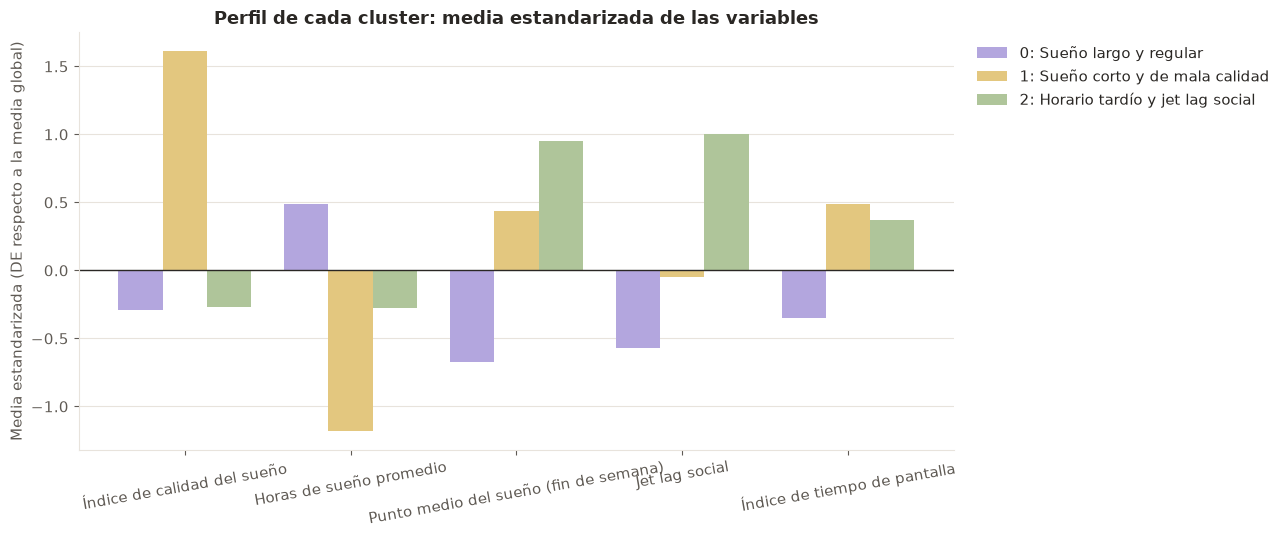

In [8]:
tabla_z = perfiles_estandarizados(pipeline, X, etiquetas)
display(tabla_z.round(2))

fig = graficar_perfiles(tabla_z, nombres)
plt.show()

Los tres clusters corresponden a perfiles bien diferenciados. El cluster 0, el más numeroso (2586 adolescentes, 53.8%), reúne a quienes duermen más y con horarios más tempranos: duermen 8.31 horas en promedio (0.49 DE por encima de la media global), su punto medio del sueño del fin de semana se sitúa en las 4.62 horas (−0.67 DE), tienen el menor jet lag social (1.75 horas, −0.57 DE) y el menor tiempo de pantalla (2.86 puntos, −0.35 DE), con una calidad del sueño algo mejor que la media (1.66 puntos, −0.29 DE). Por ello se denomina «sueño largo y regular».

El cluster 1, el más pequeño (712 adolescentes, 14.8%), se define por un sueño de mala calidad, con un índice de 3.27 puntos (1.61 DE por encima de la media), y corto, de 6.19 horas (−1.18 DE). Lo acompañan el mayor tiempo de pantalla (3.72 puntos, 0.49 DE) y un punto medio del sueño algo tardío (6.18 horas, 0.43 DE), sin diferencias en el jet lag social (−0.05 DE), y se denomina «sueño corto y de mala calidad». El cluster 2 (1512 adolescentes, 31.4%) mantiene una calidad del sueño similar a la del cluster 0 (1.67 puntos, −0.27 DE) y duerme algo menos que el promedio (7.34 horas, −0.27 DE), pero se distingue por el horario más tardío (6.91 horas de punto medio, 0.95 DE) y el mayor jet lag social (3.54 horas, 1.00 DE), con un tiempo de pantalla también elevado (3.60 puntos, 0.37 DE); se denomina «horario tardío y jet lag social».

El tiempo de pantalla no define por sí solo ningún perfil. Es más alto en los clusters 1 y 2 y más bajo en el 0, pero en ninguno es la variable que más se aleja de la media.

La proyección en las dos primeras componentes principales permite ver los clusters en un plano. Cada punto es un adolescente, coloreado según su cluster, y las cruces marcan los centroides. Los ejes indican el porcentaje de la varianza de las cinco variables estandarizadas que recoge cada componente, y la tabla de cargas muestra qué variables definen cada eje. Como la proyección conserva solo parte de la varianza, clusters que se superponen en el plano pueden estar mejor separados en el espacio completo.

,CP1,CP2
Variable,,
Índice de calidad del sueño,0.206,0.711
Horas de sueño promedio,-0.441,-0.437
Punto medio del sueño (fin de semana),0.622,-0.230
Jet lag social,0.522,-0.474
Índice de tiempo de pantalla,0.322,0.159


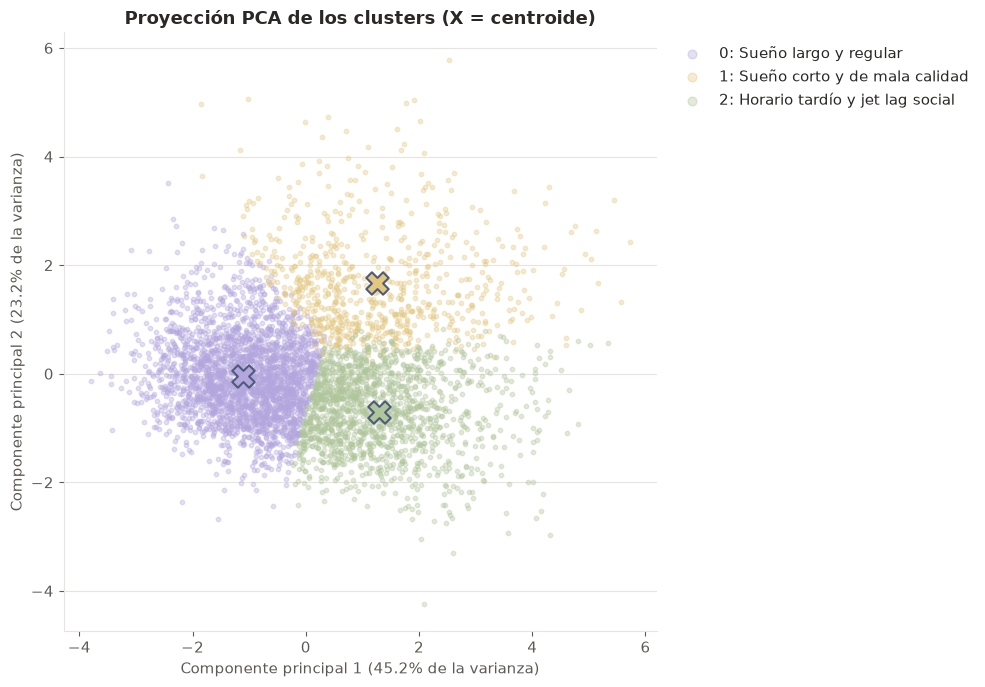

In [9]:
display(cargas_pca(pipeline, X).round(3))

fig = graficar_pca(pipeline, X, etiquetas, nombres)
plt.show()

Las dos primeras componentes principales recogen el 68.4% de la varianza de las cinco variables, el 45.2% la primera y el 23.2% la segunda. La primera refleja sobre todo el horario de sueño, con cargas de 0.622 para el punto medio del sueño y de 0.522 para el jet lag social, y en sentido opuesto las horas de sueño (−0.441); la segunda refleja la calidad del sueño (0.711), con cargas negativas de las horas de sueño (−0.437) y del jet lag social (−0.474). En el plano, el cluster de sueño largo y regular ocupa los valores bajos de la primera componente, el de horario tardío los valores altos, y el de sueño corto y de mala calidad se desplaza hacia arriba en la segunda, es decir, por su peor calidad del sueño. Los tres grupos se tocan en sus bordes, sin espacios vacíos entre ellos, lo que concuerda con la silueta baja: la partición divide una nube continua más que separar grupos aislados.

## 3. Validación Externa

La validación externa compara los clusters según variables que no se usaron para formarlos: el estado depresivo, el BDI-II y el sexo. Si los perfiles de hábitos difieren en estas variables, la segmentación captura algo relevante más allá de las propias variables de agrupamiento.

### Prevalencia de Depresión

Para cada cluster se calcula la proporción de adolescentes deprimidos (BDI-II ≥ 14) con su intervalo de confianza al 95% de Wilson, más adecuado que el de Wald para proporciones bajas, y se compara con la prevalencia global, que aparece como línea de referencia. La prueba chi-cuadrado contrasta si la prevalencia es la misma en todos los clusters, y la V de Cramér mide la intensidad de la asociación, entre 0 (ninguna) y 1 (total).

,Nombre,n,Deprimidos,Prevalencia,IC 2.5%,IC 97.5%
Cluster,,,,,,
0,Sueño largo y regular,2586,268,0.104,0.092,0.116
1,Sueño corto y de mala calidad,712,277,0.389,0.354,0.425
2,Horario tardío y jet lag social,1512,242,0.160,0.142,0.179


,Cluster × depresión
Chi-cuadrado,3.325287e+02
gl,2.000000e+00
p-valor,6.198985e-73
V de Cramér,2.629311e-01


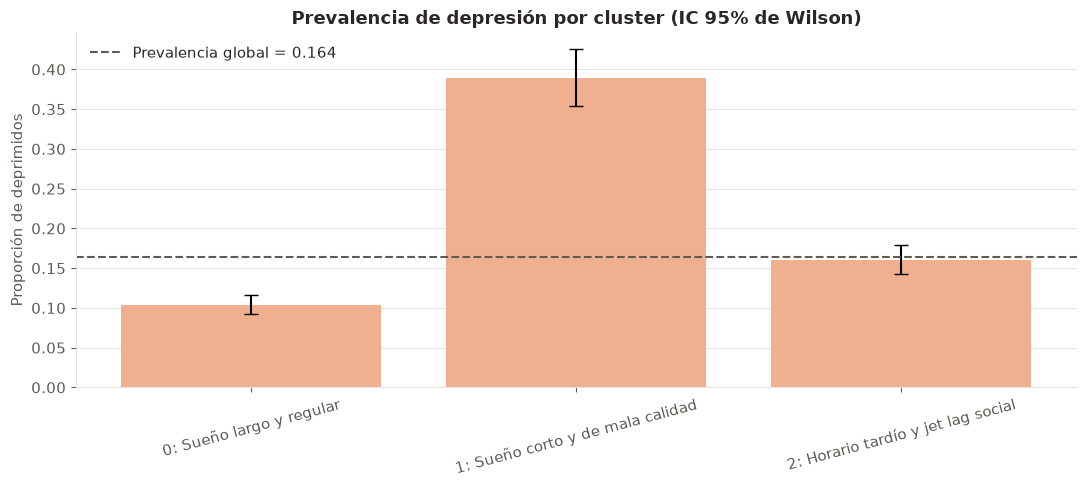

In [10]:
prevalencia = prevalencia_por_cluster(df, etiquetas, nombres)
prevalencia_global = df["depressed"].mean()

display(prevalencia.round(3))
display(pd.Series(prueba_chi_cuadrado(etiquetas, df["depressed"]), name="Cluster × depresión").to_frame())

fig = graficar_prevalencia(prevalencia, prevalencia_global)
plt.show()

La prevalencia de depresión difiere entre perfiles (χ²(2) = 332.53, p < 0.001), con una asociación de magnitud pequeña a moderada (V de Cramér = 0.263). El cluster de sueño corto y de mala calidad concentra el riesgo, con una prevalencia de 0.389 (IC 95%: 0.354–0.425), más del doble de la global (0.164), mientras que el de sueño largo y regular queda por debajo, con 0.104 (IC 95%: 0.092–0.116). El de horario tardío y jet lag social se sitúa prácticamente en la media, con 0.160 (IC 95%: 0.142–0.179), y su intervalo incluye la prevalencia global.

### BDI-II

El BDI-II es asimétrico y tiene muchos valores bajos, por lo que se compara entre clusters con la prueba de Kruskal-Wallis, basada en rangos, y se acompaña del épsilon cuadrado como tamaño de efecto, que indica la proporción de la variabilidad de los rangos atribuible al cluster. Las comparaciones por pares usan la prueba de Dunn con corrección de Holm cuando está disponible `scikit-posthocs`; en su defecto, se aplica Mann-Whitney bilateral a cada par con la misma corrección. La línea discontinua del boxplot marca el corte clínico de 14 puntos.

,Nombre,Media,DE,Mediana,Q1,Q3
Cluster,,,,,,
0,Sueño largo y regular,5.70,6.32,4.0,1.0,8.0
1,Sueño corto y de mala calidad,13.01,9.65,11.0,6.0,18.0
2,Horario tardío y jet lag social,7.25,7.56,5.0,2.0,10.0


,Kruskal-Wallis (BDI-II)
H,4.897369e+02
gl,2.000000e+00
p-valor,4.518396e-107
Épsilon cuadrado,1.018376e-01


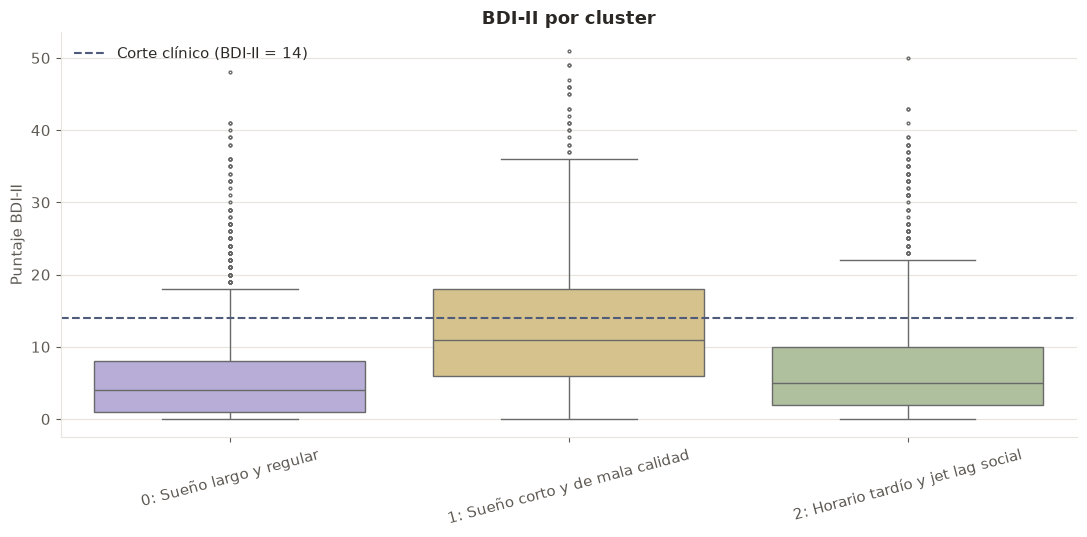

In [11]:
display(resumen_bdi(df, etiquetas, nombres).round(2))
display(pd.Series(prueba_kruskal(df, etiquetas), name="Kruskal-Wallis (BDI-II)").to_frame())

fig = graficar_bdi(df, etiquetas, nombres)
plt.show()

In [12]:
comparaciones_por_pares(df, etiquetas).round(4)

,Cluster A,Cluster B,Método,Estadístico U,p-valor,p-valor (Holm),Significativa
0,0,1,Mann-Whitney,431108.0,0.0,0.0,True
1,0,2,Mann-Whitney,1691111.5,0.0,0.0,True
2,1,2,Mann-Whitney,764198.0,0.0,0.0,True


El BDI-II mantiene el mismo orden. El cluster de sueño corto y de mala calidad tiene la puntuación más alta, 13.01 ± 9.65 puntos (mediana de 11, RIC 6–18), con una media cercana al corte clínico de 14, seguido del de horario tardío y jet lag social, con 7.25 ± 7.56 (mediana de 5, RIC 2–10), y del de sueño largo y regular, con 5.70 ± 6.32 (mediana de 4, RIC 1–8). La prueba de Kruskal-Wallis confirma diferencias entre clusters (H(2) = 489.74, p < 0.001), con un épsilon cuadrado de 0.102, de modo que el cluster explica el 10.2% de la variabilidad de los rangos del BDI-II. Las tres comparaciones por pares de Mann-Whitney resultan significativas tras la corrección de Holm (p < 0.001), por lo que incluso el perfil de horario tardío presenta síntomas algo mayores que el de sueño largo y regular.

### Composición por Sexo

Por último, se compara la proporción de chicas en cada cluster con la proporción global, que aparece como línea de referencia en las barras apiladas, y se contrasta con una prueba chi-cuadrado y la V de Cramér si la composición por sexo difiere entre perfiles.

,Nombre,Chicos,Chicas,Proporción de chicas
Cluster,,,,
0,Sueño largo y regular,1289,1297,0.502
1,Sueño corto y de mala calidad,251,461,0.647
2,Horario tardío y jet lag social,906,606,0.401


,Cluster × sexo
Chi-cuadrado,1.201238e+02
gl,2.000000e+00
p-valor,8.231120e-27
V de Cramér,1.580309e-01


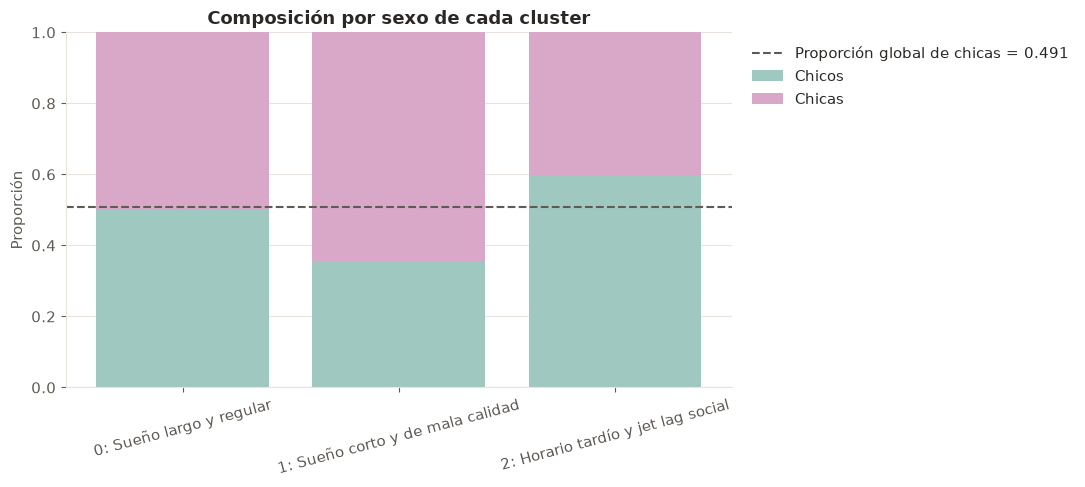

In [13]:
sexo = composicion_sexo(df, etiquetas, nombres)
proporcion_chicas = (df["sex"] == "Girl").mean()

display(sexo.round(3))
display(pd.Series(prueba_chi_cuadrado(etiquetas, df["sex"]), name="Cluster × sexo").to_frame())

fig = graficar_sexo(sexo, proporcion_chicas)
plt.show()

La composición por sexo también varía entre perfiles (χ²(2) = 120.12, p < 0.001), aunque la asociación es menor que con la depresión (V de Cramér = 0.158). Las chicas son el 64.7% del cluster de sueño corto y de mala calidad (461 de 712), frente a una proporción global de 0.491, mientras que el de horario tardío y jet lag social es mayoritariamente masculino, con un 40.1% de chicas (606 de 1512). El de sueño largo y regular reproduce la composición global, con un 50.2% de chicas.

## Conclusiones

Existe un perfil de alto riesgo: el de sueño corto y de mala calidad, que agrupa al 14.8% de los adolescentes y presenta una prevalencia de depresión de 0.389 (IC 95%: 0.354–0.425) y un BDI-II de 13.01 ± 9.65 puntos. Lo caracterizan, ante todo, la mala calidad del sueño (1.61 DE por encima de la media) y su corta duración (−1.18 DE); su tiempo de pantalla es el más alto, pero se aleja de la media mucho menos (0.49 DE). Este resultado es coherente con el modelado, donde `sleep_quality_index` fue el predictor dominante y el tiempo de pantalla tuvo un papel secundario: el perfil de horario tardío, con un tiempo de pantalla casi igual de alto (3.60 frente a 3.72 puntos) pero una calidad del sueño similar a la del perfil de sueño largo y regular, tiene una prevalencia de 0.160, prácticamente igual a la global.

Chicos y chicas no se reparten por igual entre los perfiles. Las chicas predominan en el de alto riesgo (64.7%) y los chicos en el de horario tardío (59.9%), mientras que el de sueño largo y regular está equilibrado (50.2% de chicas).

Este análisis es transversal y descriptivo. Muestra cómo se distribuyen la depresión y el sexo entre perfiles de hábitos, pero no permite concluir que pertenecer a un perfil cause la depresión ni establecer la dirección de la relación entre hábitos y síntomas.

### Guardado

Los resultados se guardan en `data/processed/clustering/`. El archivo `kmeans.joblib` contiene el Pipeline final (`StandardScaler` → `KMeans`), que recibe un DataFrame con las cinco variables de agrupamiento y devuelve el cluster de cada adolescente. `seleccion_k.csv` recoge las métricas de cada k evaluado; `asignaciones.csv`, el cluster de cada `subject_id`; `perfiles.csv`, el nombre, el tamaño, las medias y medianas de las variables, la prevalencia de depresión con su intervalo, el BDI-II medio y mediano y la proporción de chicas de cada cluster; y `metadatos.json`, el k elegido, la semilla, las variables, los parámetros de K-Means y las versiones de las librerías.

In [14]:
perfiles = tabla_perfiles(X, df, etiquetas, nombres)
metadatos = guardar_resultados(pipeline, tabla_k, df, etiquetas, perfiles, K_ELEGIDO)
perfiles.round(3)

✓ Guardado en /workspace/data/processed/clustering: kmeans.joblib, seleccion_k.csv, asignaciones.csv, perfiles.csv y metadatos.json


,cluster,nombre,n,porcentaje,media_sleep_quality_index,mediana_sleep_quality_index,media_avg_sleep_hours,mediana_avg_sleep_hours,media_midsleep_weekend_hours,mediana_midsleep_weekend_hours,media_social_jetlag_hours,mediana_social_jetlag_hours,media_screen_time_index,mediana_screen_time_index,prevalencia_depresion,prevalencia_ic_inf,prevalencia_ic_sup,bdi_media,bdi_mediana,proporcion_chicas
0,0,Sueño largo y regular,2586,53.8,1.657,1.50,8.305,8.330,4.616,4.67,1.751,1.75,2.860,2.667,0.104,0.092,0.116,5.703,4.0,0.502
1,1,Sueño corto y de mala calidad,712,14.8,3.272,3.25,6.191,6.395,6.183,6.04,2.342,2.33,3.719,3.667,0.389,0.354,0.425,13.010,11.0,0.647
2,2,Horario tardío y jet lag social,1512,31.4,1.675,1.50,7.341,7.440,6.915,6.78,3.537,3.42,3.597,3.667,0.160,0.142,0.179,7.251,5.0,0.401
